**Import the necessary libraries**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from tensorflow.keras.datasets import cifar10
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input, Conv2D, MaxPooling2D, Flatten,
    Dense, Dropout
)
from tensorflow.keras.optimizers import Adam, SGD, RMSprop
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.model_selection import train_test_split

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score
)

# Reproducibility
np.random.seed(42)
tf.random.set_seed(42)

**Load the CIFAR-10 dataset using Keras**

In [2]:
# Load CIFAR-10 dataset
(X_train_original, y_train_original), (X_test_original, y_test_original) = cifar10.load_data()

# Combine the datasets
X = np.concatenate((X_train_original, X_test_original), axis=0)
y = np.concatenate((y_train_original, y_test_original), axis=0)

# Display dataset shape
print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (60000, 32, 32, 3)
Target shape: (60000, 1)


**Split the dataset into training and testing sets**

In [3]:
# Split dataset into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Display dataset shapes
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

Training features: (48000, 32, 32, 3)
Testing features: (12000, 32, 32, 3)
Training labels: (48000, 1)
Testing labels: (12000, 1)


**Normalize the pixel values to be between 0 and 1.**

In [4]:
# Normalize pixel values
X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

# Convert labels into 1D arrays
y_train = y_train.flatten()
y_test = y_test.flatten()

# Verify normalization
print("Minimum pixel value:", X_train.min())
print("Maximum pixel value:", X_train.max())

Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [8]:
#Visualize the images
class_names = [
    'Airplane', 'Automobile', 'Bird', 'Cat', 'Deer',
    'Dog', 'Frog', 'Horse', 'Ship', 'Truck'
]

# Display class names
for i, name in enumerate(class_names):
    print(f"{i}: {name}")
    


0: Airplane
1: Automobile
2: Bird
3: Cat
4: Deer
5: Dog
6: Frog
7: Horse
8: Ship
9: Truck


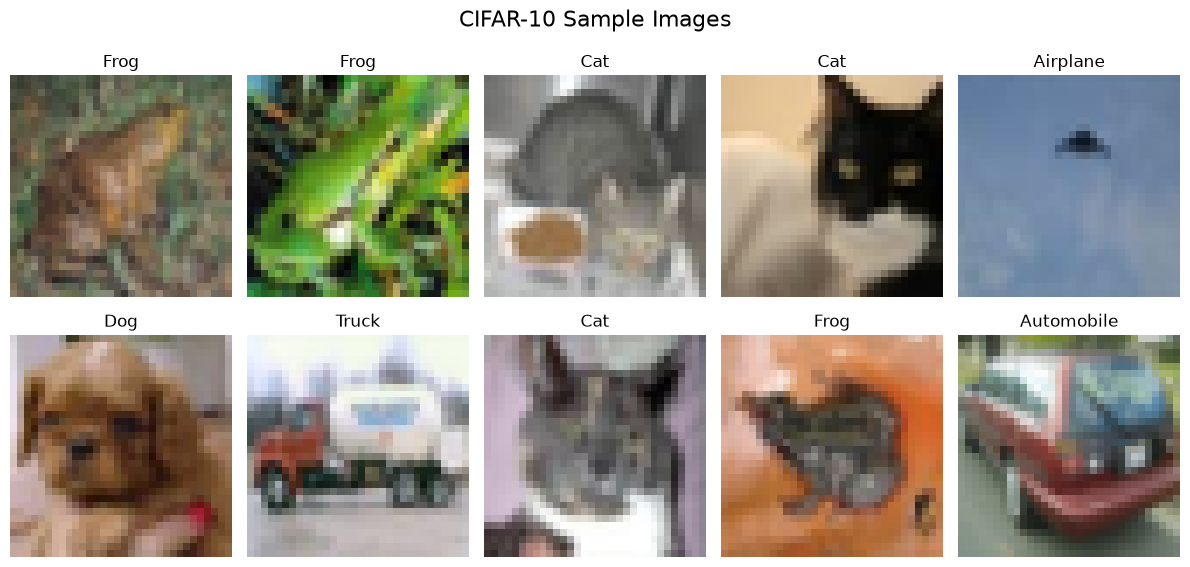

In [10]:
plt.figure(figsize=(12, 6))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    plt.imshow(X_train[i])
    plt.title(class_names[int(y_train[i])])
    plt.axis('off')

plt.suptitle("CIFAR-10 Sample Images", fontsize=16)
plt.tight_layout()
plt.show()

**Build the Neural Network Mode**

In [11]:
# Build the CNN model
model = Sequential([
    # Input layer
    Input(shape=(32, 32, 3)),

    # First convolutional layer
    Conv2D(32, (3, 3), activation='relu', padding='same'),
    MaxPooling2D((2, 2)),

    # Second convolutional layer
    Conv2D(64, (3, 3), activation='relu', padding='same'),
    MaxPooling2D((2, 2)),

    # Flatten layer
    Flatten(),

    # Fully connected layer
    Dense(128, activation='relu'),

    # Dropout to reduce overfitting
    Dropout(0.5),

    # Output layer
    Dense(10, activation='softmax')
])

# Display model architecture
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 32, 32, 32)          │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 16, 16, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 16, 16, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 8, 8, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 4096)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │         524,416 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 545,098 (2.08 MB)

 Trainable params: 545,098 (2.08 MB)

 Non-trainable params: 0 (0.00 B)

**Compile the Mode**

In [12]:
model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("CNN model compiled successfully!")

CNN model compiled successfully!


**Train the Neural Network**
To allow us to monitor how well the model generalizes during the training, we will reserve 20% of the training images for validation That is out of the 48000 images for training. additional 20% wil be reserved for validation

In [13]:
# Split training data into training and validation sets
X_train_final, X_val, y_train_final, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

print("Training images:", X_train_final.shape)
print("Validation images:", X_val.shape)
print("Testing images:", X_test.shape)

Training images: (38400, 32, 32, 3)
Validation images: (9600, 32, 32, 3)
Testing images: (12000, 32, 32, 3)


In [14]:
# Train the CNN model
history = model.fit(
    X_train_final,
    y_train_final,
    epochs=20,
    batch_size=64,
    validation_data=(X_val, y_val),
    verbose=1
)

Epoch 1/20
600/600 ━━━━━━━━━━━━━━━━━━━━ 13s 19ms/step - accuracy: 0.3997 - loss: 1.6526 - val_accuracy: 0.5494 - val_loss: 1.2726
Epoch 2/20
600/600 ━━━━━━━━━━━━━━━━━━━━ 14s 23ms/step - accuracy: 0.5302 - loss: 1.3126 - val_accuracy: 0.6101 - val_loss: 1.0962
Epoch 3/20
600/600 ━━━━━━━━━━━━━━━━━━━━ 14s 24ms/step - accuracy: 0.5770 - loss: 1.1849 - val_accuracy: 0.6378 - val_loss: 1.0253
Epoch 4/20
600/600 ━━━━━━━━━━━━━━━━━━━━ 15s 26ms/step - accuracy: 0.6133 - loss: 1.0928 - val_accuracy: 0.6653 - val_loss: 0.9635
Epoch 5/20
600/600 ━━━━━━━━━━━━━━━━━━━━ 15s 25ms/step - accuracy: 0.6354 - loss: 1.0371 - val_accuracy: 0.6732 - val_loss: 0.9251
Epoch 6/20
600/600 ━━━━━━━━━━━━━━━━━━━━ 14s 23ms/step - accuracy: 0.6589 - loss: 0.9701 - val_accuracy: 0.6907 - val_loss: 0.8955
Epoch 7/20
600/600 ━━━━━━━━━━━━━━━━━━━━ 15s 25ms/step - accuracy: 0.6735 - loss: 0.9260 - val_accuracy: 0.6872 - val_loss: 0.9111
Epoch 8/20
600/600 ━━━━━━━━━━━━━━━━━━━━ 16s 26ms/step - accuracy: 0.6887 - loss: 0.8853 - 

The Training accuracy increased steadily from 39.97% to 78.72% while for teh validation accuracy, after approximately epoch 9, validation accuracy began fluctuating around 69–71%, while training accuracy continued increasing. The CNN accuracy across 19 epoch shows a training accuracy of 78.72% and valiadation accuracy of 70.57%.

**Monitor the accuracy and loss on both the training and validation sets over multiple epochs.**

In [15]:
# Convert training history to DataFrame
history_df = pd.DataFrame(history.history)

# Add epoch numbers
history_df.index = history_df.index + 1
history_df.index.name = 'Epoch'

# Display results
print(history_df.round(4))

       accuracy    loss  val_accuracy  val_loss
Epoch                                          
1        0.3997  1.6526        0.5494    1.2726
2        0.5302  1.3126        0.6101    1.0962
3        0.5770  1.1849        0.6378    1.0253
4        0.6133  1.0928        0.6653    0.9635
5        0.6354  1.0371        0.6732    0.9251
6        0.6589  0.9701        0.6907    0.8955
7        0.6735  0.9260        0.6872    0.9111
8        0.6887  0.8853        0.6927    0.8718
9        0.7035  0.8383        0.6949    0.8870
10       0.7132  0.8069        0.6879    0.9218
11       0.7244  0.7703        0.6965    0.8883
12       0.7326  0.7447        0.6958    0.9009
13       0.7441  0.7132        0.6958    0.9095
14       0.7472  0.6864        0.6906    0.9296
15       0.7620  0.6566        0.7024    0.9109
16       0.7686  0.6331        0.6939    0.9334
17       0.7737  0.6152        0.6896    0.9523
18       0.7804  0.5931        0.7018    0.9336
19       0.7872  0.5727        0.7057   

**Evaluate the trained model**

In [16]:
# Evaluate model on test data
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Loss: {test_loss:.4f}")

Test Accuracy: 0.7028
Test Loss: 0.9791


The model correctly classified 70.28% of the unseen test images. This meanis that of the 12,000 images in teh test dataset, about 8,434 were correctly classified and 3,566 were incorrectly classified.

The test loss measures how well the model predicted probability distributions match the actual classes. a lower loss function is the goal of every model. Based on the output, the test loss of 0.971 means the model did not perform well.

**Visualize training and validation accuracy**

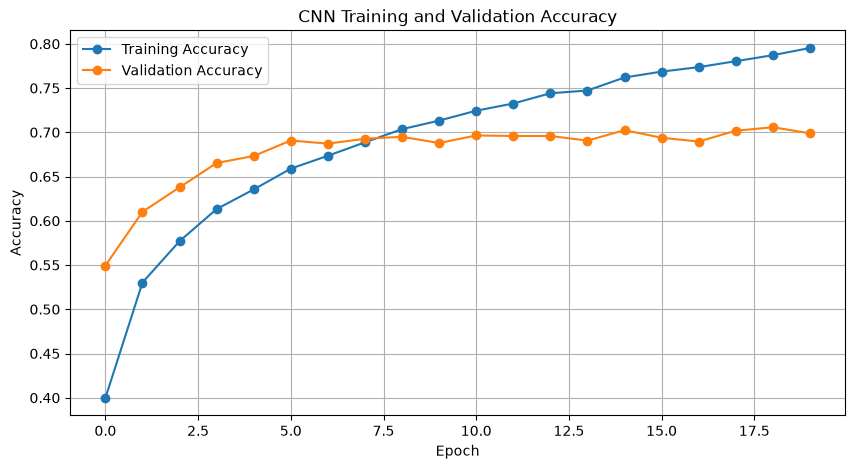

In [17]:
plt.figure(figsize=(10, 5))

plt.plot(
    history.history['accuracy'],
    label='Training Accuracy',
    marker='o'
)

plt.plot(
    history.history['val_accuracy'],
    label='Validation Accuracy',
    marker='o'
)

plt.title('CNN Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

**Visualize training and validation loss**

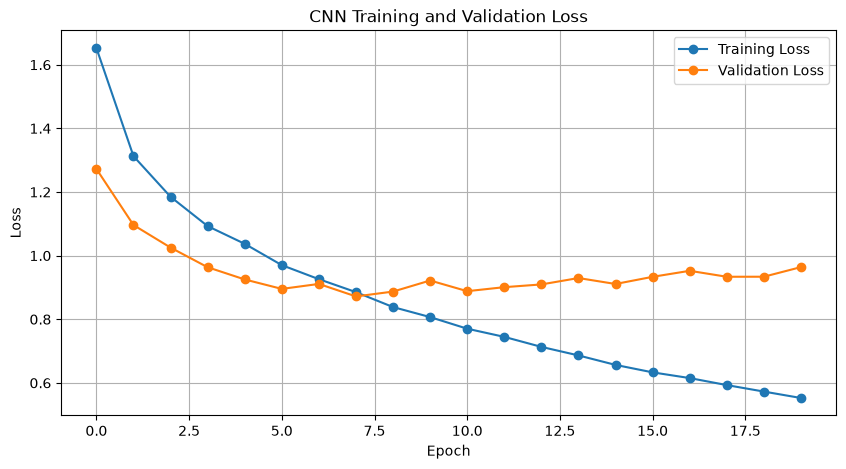

In [18]:
plt.figure(figsize=(10, 5))

plt.plot(
    history.history['loss'],
    label='Training Loss',
    marker='o'
)

plt.plot(
    history.history['val_loss'],
    label='Validation Loss',
    marker='o'
)

plt.title('CNN Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

**Check for overfitting**

In [19]:
train_accuracy = history.history['accuracy'][-1]
val_accuracy = history.history['val_accuracy'][-1]

print(f"Training Accuracy: {train_accuracy:.4f}")
print(f"Validation Accuracy: {val_accuracy:.4f}")
print(f"Accuracy Gap: {train_accuracy - val_accuracy:.4f}")

Training Accuracy: 0.7953
Validation Accuracy: 0.6989
Accuracy Gap: 0.0964


**Imrpoving the model using RMSprop**


In [20]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input, Conv2D, MaxPooling2D,
    Flatten, Dense, Dropout
)
from tensorflow.keras.optimizers import RMSprop

# Build CNN
rmsprop_model = Sequential([
    Input(shape=(32, 32, 3)),

    Conv2D(32, (3, 3), activation='relu', padding='same'),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation='relu', padding='same'),
    MaxPooling2D((2, 2)),

    Flatten(),

    Dense(128, activation='relu'),
    Dropout(0.5),

    Dense(10, activation='softmax')
])

rmsprop_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)                    │ (None, 32, 32, 32)          │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 16, 16, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_3 (Conv2D)                    │ (None, 16, 16, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 8, 8, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_1 (Flatten)                  │ (None, 4096)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 128)                 │         524,416 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 545,098 (2.08 MB)

 Trainable params: 545,098 (2.08 MB)

 Non-trainable params: 0 (0.00 B)

In [22]:
#Compile using RMSprop
rmsprop_model.compile(
    optimizer=RMSprop(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [23]:
#train the CNN
rmsprop_history = rmsprop_model.fit(
    X_train_final,
    y_train_final,
    epochs=20,
    batch_size=64,
    validation_data=(X_val, y_val),
    verbose=1
)

Epoch 1/20
600/600 ━━━━━━━━━━━━━━━━━━━━ 12s 20ms/step - accuracy: 0.3800 - loss: 1.7188 - val_accuracy: 0.5168 - val_loss: 1.3421
Epoch 2/20
600/600 ━━━━━━━━━━━━━━━━━━━━ 22s 22ms/step - accuracy: 0.5307 - loss: 1.3269 - val_accuracy: 0.6108 - val_loss: 1.1075
Epoch 3/20
600/600 ━━━━━━━━━━━━━━━━━━━━ 15s 24ms/step - accuracy: 0.5938 - loss: 1.1603 - val_accuracy: 0.6082 - val_loss: 1.1189
Epoch 4/20
600/600 ━━━━━━━━━━━━━━━━━━━━ 15s 25ms/step - accuracy: 0.6284 - loss: 1.0610 - val_accuracy: 0.6474 - val_loss: 1.0036
Epoch 5/20
600/600 ━━━━━━━━━━━━━━━━━━━━ 15s 25ms/step - accuracy: 0.6588 - loss: 0.9907 - val_accuracy: 0.6649 - val_loss: 0.9591
Epoch 6/20
600/600 ━━━━━━━━━━━━━━━━━━━━ 17s 28ms/step - accuracy: 0.6804 - loss: 0.9247 - val_accuracy: 0.6899 - val_loss: 0.9031
Epoch 7/20
600/600 ━━━━━━━━━━━━━━━━━━━━ 16s 27ms/step - accuracy: 0.6998 - loss: 0.8714 - val_accuracy: 0.6922 - val_loss: 0.9100
Epoch 8/20
600/600 ━━━━━━━━━━━━━━━━━━━━ 14s 23ms/step - accuracy: 0.7156 - loss: 0.8290 - 

In [25]:
#Evaluate the RMS prop
rmsprop_loss, rmsprop_accuracy = rmsprop_model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print(f"RMSprop Test Accuracy: {rmsprop_accuracy:.4f}")
print(f"RMSprop Test Loss: {rmsprop_loss:.4f}")

RMSprop Test Accuracy: 0.7056
RMSprop Test Loss: 1.0172


In [26]:
#Compare Adam and RMSprop
import pandas as pd

comparison = pd.DataFrame({
    'Optimizer': ['Adam', 'RMSprop'],
    'Test Accuracy': [0.7028, rmsprop_accuracy],
    'Test Loss': [0.9791, rmsprop_loss]
})

print(comparison.round(4))

  Optimizer  Test Accuracy  Test Loss
0      Adam         0.7028     0.9791
1   RMSprop         0.7056     1.0172


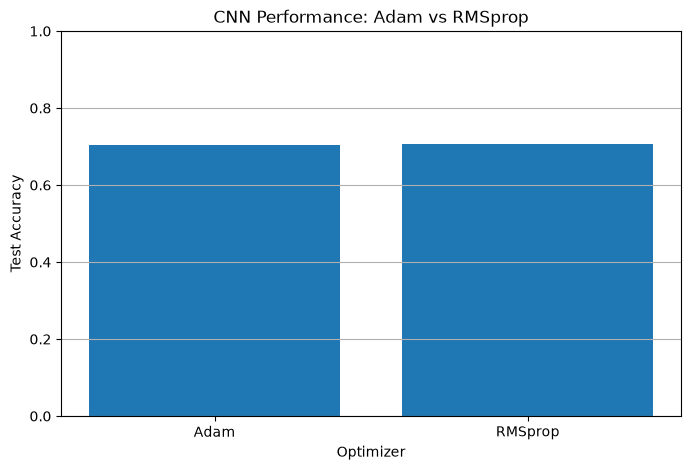

In [27]:
#Visualize accuracy comparison
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(
    comparison['Optimizer'],
    comparison['Test Accuracy']
)

plt.title('CNN Performance: Adam vs RMSprop')
plt.xlabel('Optimizer')
plt.ylabel('Test Accuracy')
plt.ylim(0, 1)
plt.grid(axis='y')
plt.show()

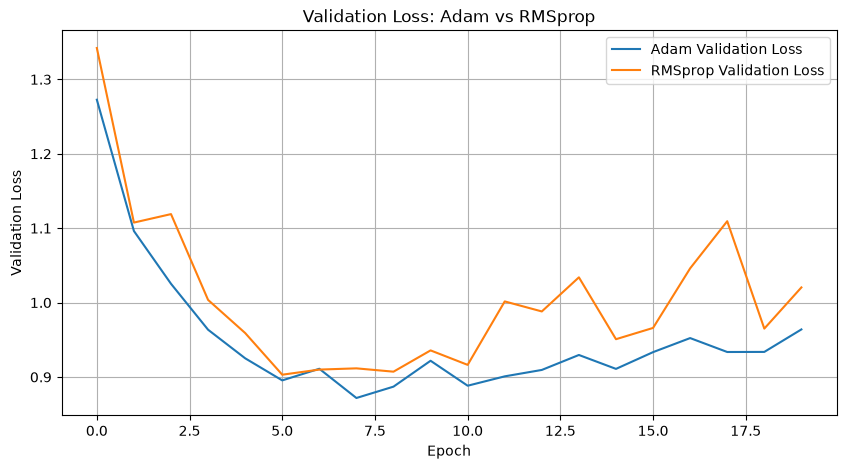

In [28]:
#Compare training and validation loss
plt.figure(figsize=(10, 5))

plt.plot(
    history.history['val_loss'],
    label='Adam Validation Loss'
)

plt.plot(
    rmsprop_history.history['val_loss'],
    label='RMSprop Validation Loss'
)

plt.title('Validation Loss: Adam vs RMSprop')
plt.xlabel('Epoch')
plt.ylabel('Validation Loss')
plt.legend()
plt.grid(True)
plt.show()

Both optimizers improved during the early epochs, but RMSprop experienced greater fluctuations as training progressed. Adam demonstrated better generalization and more consistent performance. Therefore, Adam is the preferred optimizer for this model.